### Supernova opoulation catalogue

In [ ]:
import sys
import os


import numpy as np
import matplotlib.pyplot as plt
import scipy
import astropy.units as u
from astropy.time import Time
import astropy.cosmology as acosmo
from astropy.coordinates import SkyCoord
from astropy.table import QTable
import pandas as pd
from scipy.interpolate import interp1d
import ligo.skymap.plot #used implicitely
import mhealpy as mhp
import healpy as hp
import copy


sys.path.insert(1, '/Users/cristozilleruelo/Rubicube-Ampel-HU-astro/Rubicube')
from transient_rates import R_CC, R_TDE, R_sGRB_gaus, plot_rates
from params import p_cosmology
from ic_visualization_clean import read_map, plot_map, evaluate_map, get_map_area, \
    get_moc_map_metadata, get_max_ra_dec_from_map, is_source_in_contour_area



from hop import Stream
from hop.io import StartPosition

We first compute the total numbr of core-collapse suprnovae with:
$$
N_t = \int_0^\infty \frac{R_k(z)}{1+z}\frac{dV}{dz}dz
$$

In [6]:
def get_N_k(R_k, R0, p=p_cosmology, z_max=5):
    '''
    Computes the total
    '''

    #get comologicalmodel

    #esnsure the correct units for R0:
    R0 = R0.to(u.Mpc ** -3 * u.yr**-1)

    
    cosmo = acosmo.LambdaCDM(H0=p['h0']* u.km / u.s / u.Mpc, 
                         Om0= p['omega_M'],
                        Ode0=p['omega_L'])#, Tcmb0=2.725 * u.K,
    
    z_range = np.linspace(p['z_min'], z_max, p['N_int_steps'])

    dVdz =  cosmo.differential_comoving_volume(z_range)

    y = R_k(z_range, R0=R0) / (1 + z_range) * dVdz * 4 * np.pi * u.sr
    N_k = scipy.integrate.trapezoid(y, z_range)

    return N_k

In [7]:
t = 1 * u.d
np.format_float_scientific(get_N_k(R_CC, R0=p_cosmology['R0']['SN CC'], z_max=2) * t.to(u.yr))

'5.1292759539921593e+05'

In [8]:
class Transient:
    def __init__(self, transient_prop):

        self.ra = transient_prop['ra']
        self.dec = transient_prop['dec']
        self.redshift = transient_prop['z']
        self.k = transient_prop['k']
    


In [ ]:
def generate_random_transients(R_z, R0, N_tot=None, p=p_cosmology, time=1*u.yr, z_max=5, **kwargs):
    '''  
    Generates N_total number of transients given a volumetric rate R_z and local density R0. If N_t is not speficied, its computed
    from the total integrated volumetric rate.

    Params:
    ------
    time: astropy units objet. N_tot is a quantity per year, so this specifies the time window in which we are looking at this. 

    '''
    
    time = time.to(u.yr)

    if not N_tot:
        N_tot = get_N_k(R_z, R0=R0, p=p, z_max=z_max, **kwargs) * time 
    
    sample_size = int(N_tot)
    z_grid = np.linspace(p_cosmology['z_min'], z_max, 1000)
    rates_k = R_z(z_grid, R0.to(u.Mpc ** -3 * u.yr ** -1))

    p_k = rates_k / np.sum(rates_k)
    redshift_sample = np.random.choice(z_grid, p=p_k, size=sample_size)

    ra = np.random.uniform(0, 360, size=sample_size)
    dec = np.random.uniform(-90, 90, size=sample_size)

    

    # transients = []
    # for z_i, ra_i, dec_i in zip(redshift_sample, ra, dec):
    #     transients.append(Transient({
    #         'z': z_i,
    #         'ra': ra_i,
    #         'dec': dec_i,
    #         'k': 'SN CC'
    #     }))

    
    # return transients
    return {
        'z': redshift_sample,
        'z_max': z_max,
        'ra': ra,
        'dec': dec,
        'time_window': time
    }



    

In [10]:

def create_gaussian_healpix_map(ra, dec, nside, sigma_deg):
    """
    Generates a HEALPix map with a Gaussian profile centered at a given RA/DEC.
    
    Parameters:
        ra (float): Right Ascension in degrees [0, 360]
        dec (float): Declination in degrees [-90, 90]
        nside (int): HEALPix resolution parameter (must be a power of 2)
        sigma_deg (float): Standard deviation (width) of the Gaussian in degrees
        
    Returns:
        np.ndarray: The HEALPix map array
    """
    # 1. Calculate total number of pixels
    npix = hp.nside2npix(nside)
    
    # 2. Convert target RA/DEC to HEALPix spherical coordinates (theta, phi)
    # Theta is colatitude (0 at North Pole, pi at South Pole)
    # Phi is longitude (0 to 2*pi)
    target_theta = np.radians(90.0 - dec)
    target_phi = np.radians(ra)
    
    # 3. Get spherical coordinates for the center of every pixel in the map
    pixel_indices = np.arange(npix)
    pixel_thetas, pixel_phis = hp.pix2ang(nside, pixel_indices)
    
    # 4. Calculate angular distance (angular separation) between the target 
    # center and every pixel on the sphere
    angular_distances = hp.rotator.angdist(
        [target_theta, target_phi], 
        [pixel_thetas, pixel_phis]
    )
    
    # 5. Convert sigma from degrees to radians
    sigma_rad = np.radians(sigma_deg)
    
    # 6. Compute the Gaussian profile 
    # Amplitude is normalized to 1 at the peak
    hp_map = np.exp(-0.5 * (angular_distances / sigma_rad)**2)

    #create skymap object
    gaussian_map = hp_map / np.sum(hp_map)
    m = mhp.HealpixMap(data=gaussian_map, nside=nside)
    
    skymap = QTable({
            'PROBDENSITY': gaussian_map,
            'UNIQ': m.uniq
            
        })
    
    
    return skymap, m

def generate_random_alerts(N_alerts, nside=512, sigma=0.5):
    '''
    Generates N_alerts uniformly distributed in the sky'''

    #generate N_alerts random alerts:
    alerts = []
    for i in range(N_alerts):
        ra_alert = np.random.uniform(0, 360)
        dec_alert = np.random.uniform(-90, 90)
        skymap, m = create_gaussian_healpix_map(ra_alert, dec_alert, nside, sigma)
        alerts.append([skymap, m])
        
    return alerts

In [11]:
def plot_population(population, alerts, r=1, p=0.9, plot_specific_alert=None):

    '''
    population: dict. Transient poopulation
    alerts: list of list. Randmom;y generated alerts. Each element is [QTable, HealpixMap]
    '''
    ra = population['ra']
    dec= population['dec']

    

    
    #get total map for plotting
    if isinstance(plot_specific_alert, int):
         original_alert = alerts.pop(plot_specific_alert)
    else:
        original_alert = alerts.pop() 
    sel_alert = copy.deepcopy(original_alert)
    total_map = copy.deepcopy(sel_alert)[1]
    ra_zoom, dec_zoom = get_max_ra_dec_from_map(total_map) #we zoom in on the first generated alert

    
    
    
    
    #plotting
    fig = plt.figure(figsize=(6, 6), dpi=100)
    ax = plt.axes(
        [0.05, 0.05, 0.8, 0.9],
        projection='astro degrees mollweide',
        center=SkyCoord(0 * u.rad, 0 * u.rad, frame='icrs'))
    
    ax_inset = plt.axes(
            [1.03, 0.3, 0.42, 0.42],
            projection='astro degrees zoom',
            center=SkyCoord(ra_zoom * u.deg, dec_zoom * u.deg, frame='icrs'),
            radius=r * u.deg)
    for key in ['ra', 'dec']:
        ax_inset.coords[key].set_ticks_visible(False)


    
    

    
    ax.set_title(r'$N_{total} =$ ' + np.format_float_scientific(len(ra), 1) + f' time = {population['time_window'].to(u.d)}  z_max={population["z_max"]}')

    ax_inset.set_xlabel("")
    ax_inset.set_ylabel("")
    ax.grid()
    ax.locator_params(nbins=10) #test!
    ax.mark_inset_axes(ax_inset)
    ax.connect_inset_axes(ax_inset, 'upper left')
    ax.connect_inset_axes(ax_inset, 'lower left')
    ax_inset.scalebar((0.1, 0.1), 1 * u.deg).label()
    ax_inset.compass(0.9, 0.1, 0.2)
    ax_inset.grid()
    
    
    ax_inset.set_title(fr'RA: {ra_zoom:.2f}$\degree$  DEC: {dec_zoom:.2f}$\degree$')


    
    #plot alerts
    img_inset = sel_alert[1].get_wcs_img(ax_inset)
    im = ax_inset.imshow(img_inset, cmap='Greens')
    c = plt.colorbar(im, label=r'Probability')
    
    for _, m in alerts:
        total_map += m
    img_inset = total_map.get_wcs_img(ax)
    im = ax.imshow(img_inset, cmap='Greens')

    

    #plot SN
    ax.plot(ra, dec, '.', c='orange', ms=0.01, transform=ax.get_transform('world'))

    
    #50 & 90% ontour
    skymap = copy.deepcopy(sel_alert)[0]
    skymap.sort("PROBDENSITY", reverse=True)
    sorted_metadata = get_moc_map_metadata(skymap)
    # prob = sorted_metadata['PIXELAREA'] * skymap["PROBDENSITY"]
    cumprob = np.cumsum(skymap['PROBDENSITY'])
    # searchsorted gives the FIRST index where cumprob >= target.
    i_50 = cumprob.searchsorted(0.5)
    i_90 = cumprob.searchsorted(0.9)
    
    m_prob = mhp.HealpixMap(data=cumprob, uniq=skymap['UNIQ'], density=True)
    img = m_prob.get_wcs_img(ax_inset)#, coord = coord, rasterize = rasterize)
    im = ax_inset.contour(img, levels=[0.5, 0.9], colors=['black', 'black'], linestyles=['solid', 'dashed'])

    area_50 = sorted_metadata['PIXELAREA'][:i_50].sum().to(u.deg**2)
    area_90 = sorted_metadata['PIXELAREA'][:i_90].sum().to(u.deg**2)

    #plot inset sn

    catalog = SkyCoord(ra=ra * u.deg, dec=dec * u.deg)
    center_point = SkyCoord(ra=ra_zoom * u.deg, dec=dec_zoom * u.deg)
    radius = 5 * np.sqrt(area_90) 

    
    separation = center_point.separation(catalog)
    selection_zoom = separation < radius

    ax_inset.plot(
        ra[selection_zoom],
        dec[selection_zoom],
        'o',
        c='orange', ms=1, transform=ax_inset.get_transform('world'))
    
    #we also colour the accepted pixels within a p_value
    ra_accepted, dec_accepted = is_source_in_contour_area(original_alert[1], ra[selection_zoom], dec[selection_zoom],p=p)
    ax_inset.plot(
        ra_accepted,
        dec_accepted,
        'o',
        c='cyan', ms=1, transform=ax_inset.get_transform('world'),
        label=f'{100 * p:.1f}%')
    

    

    print("Area 50%: ", area_50)
    print("Area 90%: ", area_90)

    #plot
    ax_inset.legend(framealpha=1)
    plt.show()

    return original_alert


In [16]:
z_max = 1
population = generate_random_transients(R_CC, p_cosmology['R0']['SN CC'], time=1*u.d, z_max=z_max)
alerts = generate_random_alerts(N_alerts=100)

Area 50%:  1.0884589461332324 deg2
Area 90%:  3.6063398817667327 deg2


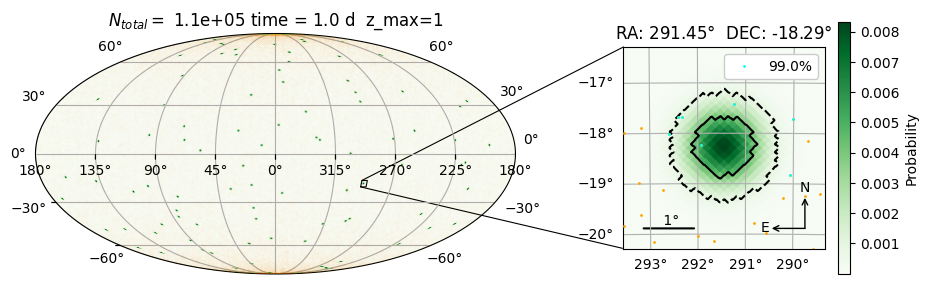

In [17]:
sel_alert = plot_population(population, alerts, r=2, p=0.99) 

In [18]:
alerts = generate_random_alerts(N_alerts=100)
n_accepted_sources_90 = []
n_accepted_sources_50 = []
n_accepted_sources_99 = []
for alert in alerts:
    ra_accepted_50, _ = is_source_in_contour_area(alert[1], population['ra'], population['dec'],
                                                          p=0.5)
    ra_accepted_90, _ = is_source_in_contour_area(alert[1], population['ra'], population['dec'],
                                                          p=0.9)
    ra_accepted_99, _ = is_source_in_contour_area(alert[1], population['ra'], population['dec'],
                                                          p=0.99)
    n_accepted_sources_50.append(len(ra_accepted_50))
    n_accepted_sources_90.append(len(ra_accepted_90))
    n_accepted_sources_99.append(len(ra_accepted_99))
    


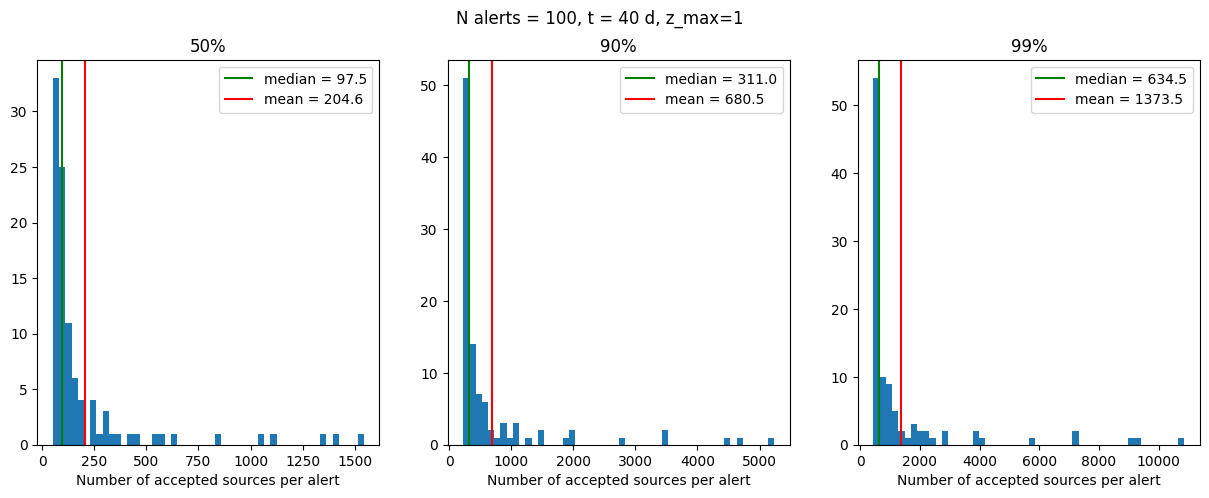

: 

: 

: 

: 

: 

: 

In [ ]:
fig, ax = plt.subplots(1,3, figsize=(15,5))

n_bins = 50

ax[0].hist(n_accepted_sources_50, bins=n_bins)
ax[0].axvline(np.median(n_accepted_sources_50), c='green', label=f'median = {np.median(n_accepted_sources_50):.1f}')
ax[0].axvline(np.mean(n_accepted_sources_50), c='red', label=f'mean = {np.mean(n_accepted_sources_50):.1f}')
ax[0].set_xlabel('Number of accepted sources per alert')
ax[0].set_title('50%')
ax[0].legend()


ax[1].hist(n_accepted_sources_90, bins=n_bins)
ax[1].axvline(np.median(n_accepted_sources_90), c='green', label=f'median = {np.median(n_accepted_sources_90):.1f}')
ax[1].axvline(np.mean(n_accepted_sources_90), c='red', label=f'mean = {np.mean(n_accepted_sources_90):.1f}')
ax[1].set_xlabel('Number of accepted sources per alert')
ax[1].set_title('90%')
ax[1].legend()


ax[2].hist(n_accepted_sources_99, bins=n_bins)
ax[2].axvline(np.median(n_accepted_sources_99), c='green', label=f'median = {np.median(n_accepted_sources_99):.1f}')
ax[2].axvline(np.mean(n_accepted_sources_99), c='red', label=f'mean = {np.mean(n_accepted_sources_99):.1f}')
ax[2].set_xlabel('Number of accepted sources per alert')
ax[2].set_title('99%')
ax[2].legend()

# for ax_i in ax:
    # ax_i.set_xlim(0, 200)

plt.suptitle(f'N alerts = 100, t = 40 d, z_max={z_max}')
plt.show()

Area 50%:  1.0753449829268078 deg2
Area 90%:  3.6063398817667327 deg2


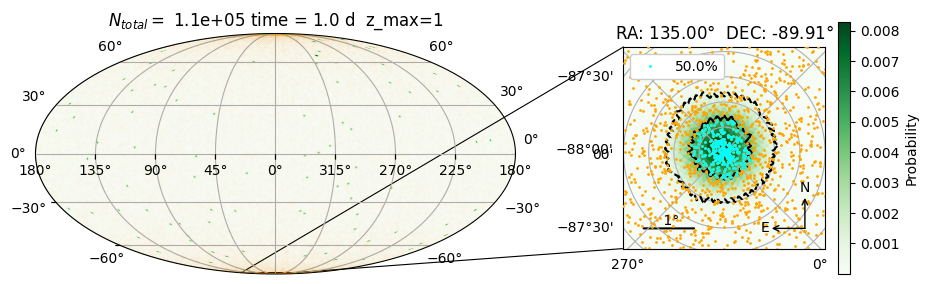

604

In [19]:
max_source_alert = int(np.argmax(n_accepted_sources_90))
sel_alert = plot_population(population, alerts, r=2, p=0.5, plot_specific_alert=max_source_alert) 
n_accepted_sources_90[max_source_alert]

In [ ]:


ra, _ = is_source_in_contour_area(alerts[max_source_alert][1], population['ra'], population['dec'],p=0.9)
len(ra)

#talk to APC people, they don't know much about what goes on inside desy
#connect to hamburg campus
#postod reps are super active at zeuthen

7

: 

: 

: 

/var/folders/9g/fpz1sy1x4jbc8fm9s02wgv9c0000gn/T/ipykernel_2336/1936191292.py:58: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax_inset.legend()


Area 50%:  1.0884589461332324 deg2
Area 90%:  3.6063398817667327 deg2


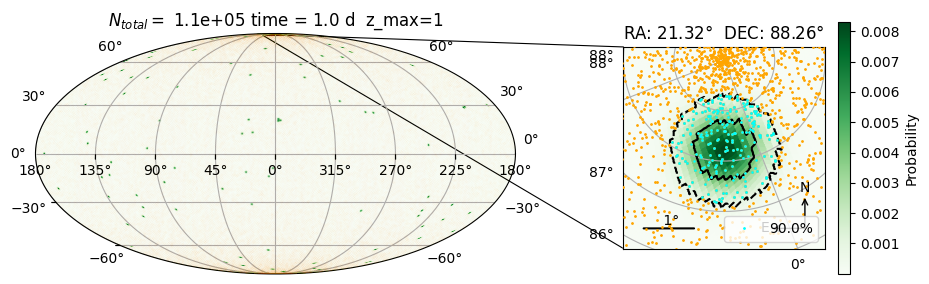

: 

: 

: 

In [ ]:
for i in range(len(alerts)):
    ra, dec = get_max_ra_dec_from_map(alerts[i][1])
    if int(np.abs(np.abs(dec) - 90)) < 3:
        # print(np.abs(dec) - 90)
        alert_ind = i
        break 
sel_alert = plot_population(population, alerts, r=2, p=0.9, plot_specific_alert=alert_ind) 

In [ ]:
ra_zoom = 270
dec_zoom = 0

# sel_criteria = ((ra_zoom - population['ra']) ** 2 + (dec_zoom - population['dec']) ** 2 < 3 * 3)
catalog = SkyCoord(ra=population['ra'] * u.deg, dec=population['dec'] * u.deg)
center_point = SkyCoord(ra=ra_zoom * u.deg, dec=dec_zoom * u.deg)
radius = 3.0 * u.deg

# 3. Calculate angular separation between the center point and all catalog sources
separation = center_point.separation(catalog)

# 4. Create your selection mask
sel_criteria = separation < radius

theta = np.linspace(0, 2 * np.pi, 100)

# Calculate RA and Dec points for the circle
# Dec_offset is straightforward, but RA_offset must be divided by cos(dec_center)
dec_circle = dec_center + radius * np.sin(theta)
ra_circle = ra_center_deg + (radius * np.cos(theta)) / np.cos(np.radians(dec_center))


population['ra'][sel_criteria]
population['dec'][sel_criteria]

array([-1.39606972,  0.78852522, -0.02718256, -2.61161958, -1.86611133,
       -0.75906308, -1.7118623 ,  1.38506636,  1.01917304, -1.79816425,
        1.5370999 ,  0.63809705,  1.36585429, -0.11425086,  2.18091851,
        1.87448402,  2.04956672,  0.61698589, -1.23031691,  0.10040053,
       -1.03277389,  1.28697986, -0.87753035, -0.93159816, -2.80642031,
       -2.36058507, -0.28538413, -2.49040089,  2.44303113,  2.21691782,
       -2.13267512, -0.30666167,  0.04112265, -1.41674596,  1.52934024,
       -2.13718459,  1.74858466, -1.88820927,  2.16639557,  1.85800876,
       -0.48687526,  0.64176331,  0.85350014, -1.05826937,  0.96682514,
        1.90206165, -0.96980812,  2.02549355])

: 

: 

: 

In [22]:
p_cosmology['R0']['SN CC'].to(u.Mpc ** -3 * u.yr**-1).value

np.float64(0.00010099999999999999)